# 04 - Churn analytics, machine learning and executive visuals

**Business case:** Spotify used as a hypothetical case study (a subscription-based digital retailer). All data is synthetic, not Spotify's real data.
**Data:** synthetic sample built through the bronze / silver / gold pipeline (see `gold_layer`).
**Reads:** `spotify_cata.gold.dimuser` (current SCD2 rows), `spotify_cata.gold.factstream_enriched`.

Sections: 0 checks, 1 feature table, 2 churn model, 3 evaluation, 4 executive charts, 5 optional clustering.

In [0]:
for t in ["dimuser", "dimtrack", "dimdate", "dimartist", "factstream_enriched"]:
    print(t, spark.table(f"spotify_cata.gold.{t}").count())

spark.table("spotify_cata.gold.dimuser").printSchema()
spark.table("spotify_cata.gold.factstream_enriched").printSchema()

dimuser 501
dimtrack 500
dimdate 365
dimartist 500
factstream_enriched 1000
root
 |-- user_id: integer (nullable = true)
 |-- user_name: string (nullable = true)
 |-- country: string (nullable = true)
 |-- subscription_type: string (nullable = true)
 |-- start_date: date (nullable = true)
 |-- end_date: date (nullable = true)
 |-- updated_at: timestamp (nullable = true)
 |-- __START_AT: timestamp (nullable = true)
 |-- __END_AT: timestamp (nullable = true)

root
 |-- stream_id: long (nullable = true)
 |-- listen_duration: integer (nullable = true)
 |-- user_id: integer (nullable = true)
 |-- user_name: string (nullable = true)
 |-- track_id: integer (nullable = true)
 |-- track_name: string (nullable = true)
 |-- date_key: integer (nullable = true)
 |-- date: date (nullable = true)



In [0]:
# One current row per user is required (SCD2 keeps history rows with __END_AT filled in).
cur = spark.table("spotify_cata.gold.dimuser").where("__END_AT IS NULL")
print("current rows:", cur.count(), "| distinct users:", cur.select("user_id").distinct().count())

current rows: 500 | distinct users: 500


## 1. Feature table (one row per user)
Label: `churned = 1` when the user has NO streams after a cutoff date (inactive = lost). The `end_date` column is empty in this synthetic data, so inactivity is used as the churn definition.
Features use only activity BEFORE the cutoff; the label uses activity AFTER it, so the model predicts the future instead of repeating the label.

In [0]:
features = spark.sql("""
WITH bounds AS (
  SELECT MIN(`date`) AS d0, MAX(`date`) AS d1
  FROM spotify_cata.gold.factstream_enriched
),
cut AS (
  -- cutoff = 70% of the way through the stream history; later activity is only used for the label
  SELECT DATE_ADD(d0, CAST(0.7 * DATEDIFF(d1, d0) AS INT)) AS cutoff FROM bounds
),
usage AS (
  SELECT f.user_id,
         COUNT(*)                 AS total_streams,
         SUM(f.listen_duration)   AS total_listen,
         AVG(f.listen_duration)   AS avg_listen,
         COUNT(DISTINCT f.track_id) AS distinct_tracks,
         MAX(f.`date`)            AS last_stream_date
  FROM spotify_cata.gold.factstream_enriched f CROSS JOIN cut c
  WHERE f.`date` <= c.cutoff
  GROUP BY f.user_id
),
future AS (
  SELECT DISTINCT f.user_id
  FROM spotify_cata.gold.factstream_enriched f CROSS JOIN cut c
  WHERE f.`date` > c.cutoff
)
SELECT u.user_id,
       u.country,
       u.subscription_type,
       DATEDIFF(c.cutoff, u.start_date)             AS tenure_days,
       a.total_streams,
       a.total_listen,
       a.avg_listen,
       a.distinct_tracks,
       DATEDIFF(c.cutoff, a.last_stream_date)       AS days_since_last_stream,
       CASE WHEN fu.user_id IS NULL THEN 1 ELSE 0 END AS churned
FROM spotify_cata.gold.dimuser u
CROSS JOIN cut c
JOIN usage a ON a.user_id = u.user_id
LEFT JOIN future fu ON fu.user_id = u.user_id
WHERE u.__END_AT IS NULL
""")

# Save as an external gold table (explicit path avoids the managed-storage problem in this workspace).
(features.write.format("delta").mode("overwrite")
    .option("path", "abfss://gold@storageazureshan.dfs.core.windows.net/churn_features")
    .saveAsTable("spotify_cata.gold.churn_features"))

display(features.groupBy("churned").count())

churned,count
0,167
1,196


## 2. Churn model (logistic regression)

`class_weight="balanced"` stops the model ignoring the minority class.
Country is left out of the model (hundreds of levels for a few hundred users would overfit) but is used in the charts.

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, RocCurveDisplay)

pdf = features.toPandas()

num_cols = ["tenure_days", "total_streams", "total_listen", "avg_listen",
            "distinct_tracks", "days_since_last_stream"]
cat_cols = ["subscription_type"]

pdf[num_cols] = pdf[num_cols].astype(float).fillna(0)

X = pdf[num_cols + cat_cols]
y = pdf["churned"].astype(int)

counts = y.value_counts()
print("Class counts:\n", counts)
if counts.min() < 10:
    raise ValueError("Too few examples of one class for a reliable churn model - use section 5 instead.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

model = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
model.fit(X_train, y_train)

Class counts:
 churned
1    196
0    167
Name: count, dtype: int64


,steps,"[('prep', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 3. Evaluation
Accuracy alone is misleading when classes are unbalanced, so report AUC, precision, recall and a baseline.
With synthetic data an AUC close to 0.5 is a legitimate finding: it means the features carry little signal.

In [0]:
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

baseline = max(y_test.mean(), 1 - y_test.mean())
print("Majority-class baseline accuracy:", round(baseline, 3))
print("Test ROC AUC:", round(roc_auc_score(y_test, proba), 3))
print()
print(classification_report(y_test, pred, digits=3))
print("Confusion matrix (rows = actual, cols = predicted):")
print(confusion_matrix(y_test, pred))

# Small data gives unstable splits, so also check 5-fold cross-validation.
cv = cross_val_score(model, X, y, cv=5, scoring="roc_auc")
print("5-fold CV ROC AUC: mean", round(cv.mean(), 3), "| std", round(cv.std(), 3))

Majority-class baseline accuracy: 0.538
Test ROC AUC: 0.451

              precision    recall  f1-score   support

           0      0.410     0.381     0.395        42
           1      0.500     0.531     0.515        49

    accuracy                          0.462        91
   macro avg      0.455     0.456     0.455        91
weighted avg      0.459     0.462     0.460        91

Confusion matrix (rows = actual, cols = predicted):
[[16 26]
 [23 26]]
5-fold CV ROC AUC: mean 0.488 | std 0.063


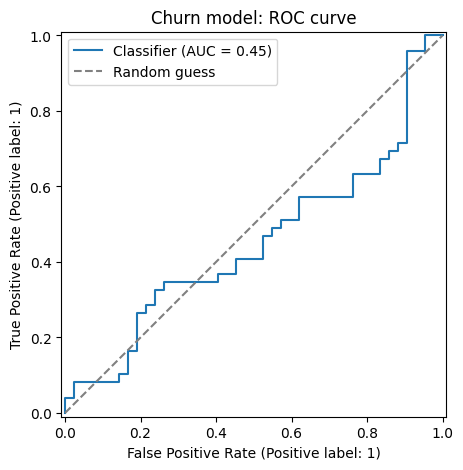

In [0]:
fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, proba, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
ax.set_title("Churn model: ROC curve")
ax.legend()
plt.show()

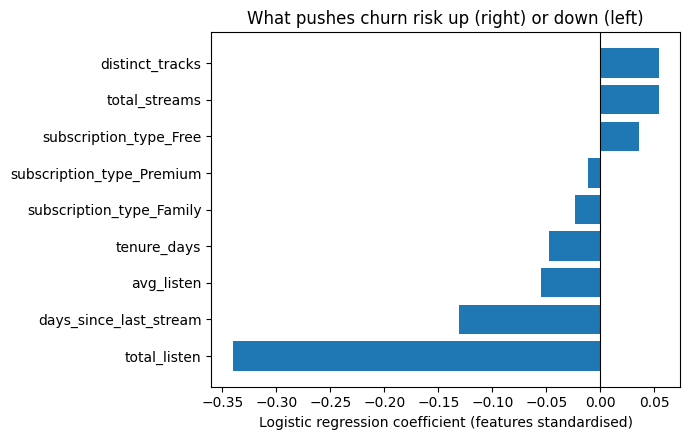

In [0]:
names = model.named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
coefs = model.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": names, "coefficient": coefs}).sort_values("coefficient")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(coef_df["feature"], coef_df["coefficient"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("What pushes churn risk up (right) or down (left)")
ax.set_xlabel("Logistic regression coefficient (features standardised)")
plt.tight_layout()
plt.show()

## 4. Executive charts


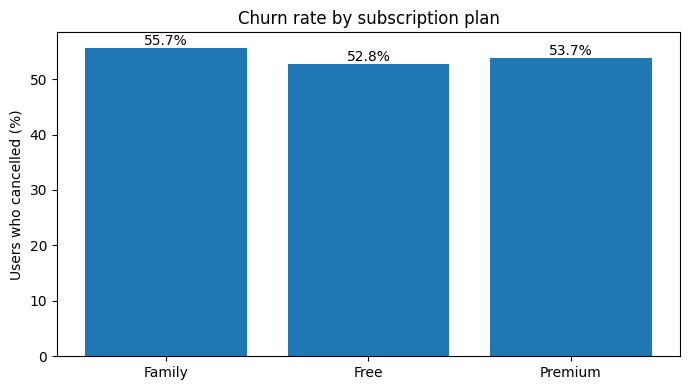

In [0]:
# Chart 1: churn rate by plan
plan = pdf.groupby("subscription_type")["churned"].agg(["mean", "count"]).reset_index()
plan["churn_pct"] = plan["mean"] * 100

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(plan["subscription_type"], plan["churn_pct"])
ax.set_title("Churn rate by subscription plan")
ax.set_ylabel("Users who cancelled (%)")
for i, v in enumerate(plan["churn_pct"]):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

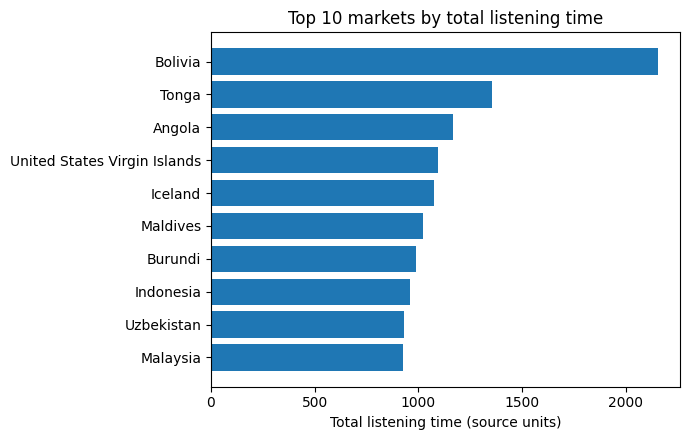

In [0]:
# Chart 2: top 10 markets by total listening time
# Units of listen_duration are as stored in the source (confirm seconds/minutes before labelling on a slide).
top = (pdf.groupby("country")["total_listen"].sum()
         .sort_values(ascending=False).head(10).sort_values())

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values)
ax.set_title("Top 10 markets by total listening time")
ax.set_xlabel("Total listening time (source units)")
plt.tight_layout()
plt.show()

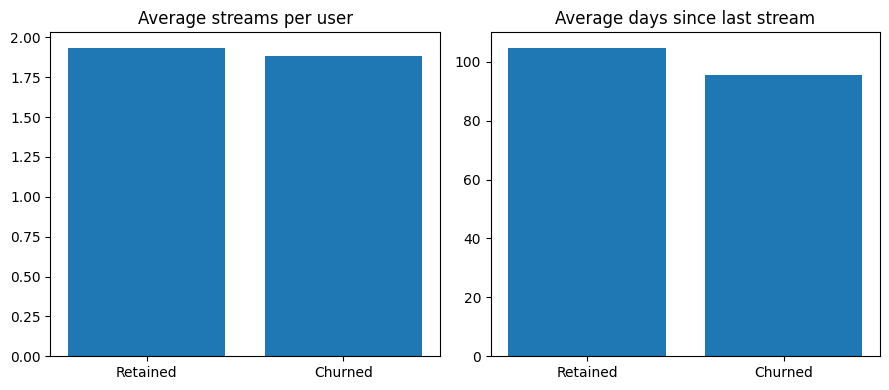

In [0]:
# Chart 3: engagement of retained vs churned users
eng = pdf.groupby("churned")[["total_streams", "days_since_last_stream"]].mean()
eng.index = ["Retained" if i == 0 else "Churned" for i in eng.index]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].bar(eng.index, eng["total_streams"])
axes[0].set_title("Average streams per user")
axes[1].bar(eng.index, eng["days_since_last_stream"])
axes[1].set_title("Average days since last stream")
plt.tight_layout()
plt.show()

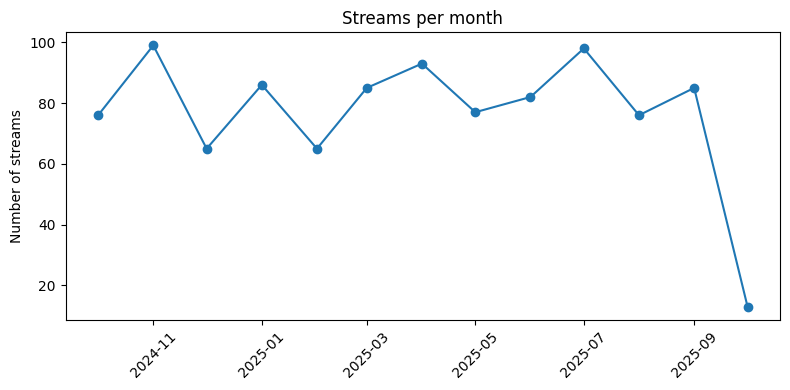

In [0]:
# Chart 4: monthly streaming trend
trend = spark.sql("""
SELECT DATE_TRUNC('month', `date`) AS month, COUNT(*) AS streams
FROM spotify_cata.gold.factstream_enriched
GROUP BY 1
ORDER BY 1
""").toPandas()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trend["month"], trend["streams"], marker="o")
ax.set_title("Streams per month")
ax.set_ylabel("Number of streams")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [0]:
# Optional: save any figure as an image for the slides.
# After running a chart cell, use the image's download option in the notebook output (right-click > Save image).

## 5. Optional fallback: customer segments (k-means)
Use this if the churn labels are too unbalanced for section 2, or as a second technique.
Unsupervised, so there is no accuracy score; judge it by whether the segments are distinct and useful.

In [0]:
from sklearn.cluster import KMeans

seg_cols = ["tenure_days", "total_streams", "avg_listen", "distinct_tracks", "days_since_last_stream"]
seg = pdf[seg_cols].astype(float).fillna(0)
scaled = StandardScaler().fit_transform(seg)

km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(scaled)
pdf["segment"] = km.labels_

summary = pdf.groupby("segment").agg(
    users=("user_id", "count"),
    avg_streams=("total_streams", "mean"),
    avg_days_inactive=("days_since_last_stream", "mean"),
    churn_rate=("churned", "mean"),
).round(2)
display(spark.createDataFrame(summary.reset_index()))

segment,users,avg_streams,avg_days_inactive,churn_rate
0,104,1.47,49.73,0.59
1,81,1.22,189.04,0.53
2,93,3.49,71.69,0.53
3,85,1.35,106.82,0.51


In [0]:
# List the gold tables
display(spark.sql("SHOW TABLES IN spotify_cata.gold"))

# Columns of every gold table
for t in ["dimuser", "dimtrack", "dimartist", "dimdate", "factstream_enriched"]:
    print("====", t)
    display(spark.sql(f"DESCRIBE TABLE spotify_cata.gold.{t}"))

database,tableName,isTemporary
gold,churn_features,false
gold,dimartist,false
gold,dimdate,false
gold,dimtrack,false
gold,dimuser,false
gold,factstream_enriched,false


==== dimuser


col_name,data_type,comment
user_id,int,null
user_name,string,null
country,string,null
subscription_type,string,null
start_date,date,null
end_date,date,null
updated_at,timestamp,null
__START_AT,timestamp,null
__END_AT,timestamp,null


==== dimtrack


col_name,data_type,comment
track_id,int,null
track_name,string,null
artist_id,int,null
album_name,string,null
duration_sec,int,null
release_date,date,null
updated_at,timestamp,null
_rescued_data,string,null
durationFlag,string,null


==== dimartist


col_name,data_type,comment
artist_id,int,null
artist_name,string,null
genre,string,null
country,string,null
updated_at,timestamp,null


==== dimdate


col_name,data_type,comment
date_key,int,null
date,date,null
day,int,null
month,int,null
year,int,null
weekday,string,null


==== factstream_enriched


col_name,data_type,comment
stream_id,bigint,null
listen_duration,int,null
user_id,int,null
user_name,string,null
track_id,int,null
track_name,string,null
date_key,int,null
date,date,null


In [0]:
# Users who have more than one row = history was kept
display(spark.sql("""
SELECT user_id, COUNT(*) AS versions
FROM spotify_cata.gold.dimuser
GROUP BY user_id HAVING COUNT(*) > 1
"""))

# The before/after for user 148 (screenshot this one)
display(spark.sql("""
SELECT user_id, country, subscription_type, __START_AT, __END_AT
FROM spotify_cata.gold.dimuser
WHERE user_id = 148
ORDER BY __START_AT
"""))

user_id,versions
148,2


user_id,country,subscription_type,__START_AT,__END_AT
148,Zambia,Family,2025-09-18T19:49:55.000Z,2026-10-22T02:05:43.993Z
148,Testland,Family,2026-10-22T02:05:43.993Z,null


In [0]:
pdf = spark.table("spotify_cata.gold.churn_features").toPandas()
y = pdf["churned"].astype(int)
print(y.value_counts())
print("Total users:", len(pdf))

churned
1    196
0    167
Name: count, dtype: int64
Total users: 363


In [0]:
# Show the files in each layer 
for c in ["bronze", "silver", "gold"]:
    print("====", c)
    display(dbutils.fs.ls(f"abfss://{c}@storageazureshan.dfs.core.windows.net/"))

# Show the watermark file contents 
print(dbutils.fs.head("abfss://bronze@storageazureshan.dfs.core.windows.net/DimUser_cdc/cdc.json"))

==== bronze


path,name,size,modificationTime
abfss://bronze@storageazureshan.dfs.core.windows.net/DimArtist/,DimArtist/,0,1792421847000
abfss://bronze@storageazureshan.dfs.core.windows.net/DimArtist_cdc/,DimArtist_cdc/,0,1792208830000
abfss://bronze@storageazureshan.dfs.core.windows.net/DimDate/,DimDate/,0,1792421789000
abfss://bronze@storageazureshan.dfs.core.windows.net/DimDate_cdc/,DimDate_cdc/,0,1792208843000
abfss://bronze@storageazureshan.dfs.core.windows.net/DimTrack/,DimTrack/,0,1792421724000
abfss://bronze@storageazureshan.dfs.core.windows.net/DimTrack_cdc/,DimTrack_cdc/,0,1792208786000
abfss://bronze@storageazureshan.dfs.core.windows.net/DimUser/,DimUser/,0,1792421664000
abfss://bronze@storageazureshan.dfs.core.windows.net/DimUser_cdc/,DimUser_cdc/,0,1791197130000
abfss://bronze@storageazureshan.dfs.core.windows.net/FactStream/,FactStream/,0,1792421922000
abfss://bronze@storageazureshan.dfs.core.windows.net/FactStream_cdc/,FactStream_cdc/,0,1792418499000


==== silver


path,name,size,modificationTime
abfss://silver@storageazureshan.dfs.core.windows.net/DimArt/,DimArt/,0,0
abfss://silver@storageazureshan.dfs.core.windows.net/DimArtist/,DimArtist/,0,0
abfss://silver@storageazureshan.dfs.core.windows.net/DimDate/,DimDate/,0,0
abfss://silver@storageazureshan.dfs.core.windows.net/DimTrack/,DimTrack/,0,0
abfss://silver@storageazureshan.dfs.core.windows.net/DimUser/,DimUser/,0,0
abfss://silver@storageazureshan.dfs.core.windows.net/FactStream/,FactStream/,0,0


==== gold


path,name,size,modificationTime
abfss://gold@storageazureshan.dfs.core.windows.net/DimUser/,DimUser/,0,0
abfss://gold@storageazureshan.dfs.core.windows.net/churn_features/,churn_features/,0,0
abfss://gold@storageazureshan.dfs.core.windows.net/dimartist/,dimartist/,0,0
abfss://gold@storageazureshan.dfs.core.windows.net/dimdate/,dimdate/,0,0
abfss://gold@storageazureshan.dfs.core.windows.net/dimtrack/,dimtrack/,0,0
abfss://gold@storageazureshan.dfs.core.windows.net/factstream_enriched/,factstream_enriched/,0,0


﻿{"cdc":"2025-10-07T19:49:56"}



In [0]:
for t in ["dimuser", "dimtrack", "dimartist", "dimdate", "factstream_enriched"]:
    print("====", t, "rows:", spark.table(f"spotify_cata.gold.{t}").count())
    display(spark.table(f"spotify_cata.gold.{t}").limit(10))

==== dimuser rows: 501


user_id,user_name,country,subscription_type,start_date,end_date,updated_at,__START_AT,__END_AT
463,JESSICA LEWIS,Slovenia,Free,2025-03-08,null,2025-10-06T19:49:55.000Z,2025-10-06T19:49:55.000Z,null
471,JOSHUA BUTLER,Ethiopia,Free,2025-09-14,null,2025-09-25T19:49:55.000Z,2025-09-25T19:49:55.000Z,null
496,ANDREW MATTHEWS,Taiwan,Family,2025-08-08,null,2025-09-17T19:49:55.000Z,2025-09-17T19:49:55.000Z,null
243,MARTHA MARTIN,Chad,Premium,2024-05-11,null,2025-10-06T19:49:55.000Z,2025-10-06T19:49:55.000Z,null
392,JENNIFER VILLANUEVA,Serbia,Free,2025-02-14,null,2025-10-06T19:49:55.000Z,2025-10-06T19:49:55.000Z,null
31,TAMMY COOK,Bolivia,Premium,2025-02-15,null,2025-10-02T19:49:55.000Z,2025-10-02T19:49:55.000Z,null
85,LISA SHERMAN,Japan,Family,2024-01-31,null,2025-09-11T19:49:55.000Z,2025-09-11T19:49:55.000Z,null
137,AMY WEEKS,Sao Tome and Principe,Family,2024-07-02,null,2025-09-09T19:49:55.000Z,2025-09-09T19:49:55.000Z,null
251,JERRY BOOTH,Lithuania,Family,2023-11-04,null,2025-09-17T19:49:55.000Z,2025-09-17T19:49:55.000Z,null
451,PHILIP SAVAGE,Saint Pierre and Miquelon,Free,2024-01-16,null,2025-10-05T19:49:55.000Z,2025-10-05T19:49:55.000Z,null


==== dimtrack rows: 500


track_id,track_name,artist_id,album_name,duration_sec,release_date,updated_at,_rescued_data,durationFlag
1,Stand alone intangible encryption,434,Technology Album,234,2021-02-09,2025-09-12T19:49:55.000Z,null,medium
2,Programmable contextually based forecast,418,Current Album,110,2023-09-30,2025-09-26T19:49:55.000Z,null,low
3,Enhanced tertiary Internet solution,35,Born Album,195,2022-01-11,2025-09-11T19:49:55.000Z,null,medium
4,Mandatory user facing framework,54,Ball Album,167,2023-06-30,2025-10-02T19:49:55.000Z,null,medium
5,Multi layered needs based concept,340,Doctor Album,137,2022-06-08,2025-10-02T19:49:55.000Z,null,low
6,Synchronized high level complexity,384,City Album,250,2021-10-16,2025-09-22T19:49:55.000Z,null,medium
7,Total human resource structure,317,Parent Album,194,2022-08-02,2025-10-07T19:49:55.000Z,null,medium
8,Exclusive multimedia matrices,37,Owner Album,206,2022-06-22,2025-10-02T19:49:55.000Z,null,medium
9,Digitized multimedia hardware,165,Hand Album,342,2023-12-03,2025-10-02T19:49:55.000Z,null,high
10,Phased dynamic utilization,15,Hair Album,199,2023-12-17,2025-10-07T19:49:55.000Z,null,medium


==== dimartist rows: 500


artist_id,artist_name,genre,country,updated_at
148,Dawn Graham,Hip-Hop,Anguilla,2025-10-05T19:49:55.000Z
463,Michael Irwin,Pop,Tokelau,2025-09-23T19:49:55.000Z
471,Alex Mcclure,Jazz,Reunion,2025-09-13T19:49:55.000Z
496,Tim Tucker,Electronic,China,2025-10-05T19:49:55.000Z
243,Leslie Holt,Jazz,Myanmar,2025-09-20T19:49:55.000Z
392,Jason Harrell,Jazz,French Polynesia,2025-10-07T19:49:55.000Z
31,Alexandra Decker,Hip-Hop,Liechtenstein,2025-09-10T19:49:55.000Z
85,Douglas White,Hip-Hop,Antigua and Barbuda,2025-09-15T19:49:55.000Z
137,Charles Perry,Electronic,Zimbabwe,2025-10-04T19:49:55.000Z
251,Mary Moore,Hip-Hop,Bahamas,2025-10-03T19:49:55.000Z


==== dimdate rows: 365


date_key,date,day,month,year,weekday
20250528,2025-05-28,28,5,2025,Wednesday
20250922,2025-09-22,22,9,2025,Monday
20250924,2025-09-24,24,9,2025,Wednesday
20241025,2024-10-25,25,10,2024,Friday
20250201,2025-02-01,1,2,2025,Saturday
20250210,2025-02-10,10,2,2025,Monday
20250215,2025-02-15,15,2,2025,Saturday
20250614,2025-06-14,14,6,2025,Saturday
20250925,2025-09-25,25,9,2025,Thursday
20250305,2025-03-05,5,3,2025,Wednesday


==== factstream_enriched rows: 1000


stream_id,listen_duration,user_id,user_name,track_id,track_name,date_key,date
1,156,361,JOE MOORE,74,Cross group 24hour migration,20250518,2025-05-18
2,47,321,KYLE HOLDEN,288,Secured 24hour capability,20250519,2025-05-19
3,214,275,RACHEL YORK,340,Customizable dedicated success,20250307,2025-03-07
4,14,43,DAVID TAYLOR,373,Realigned 3rdgeneration analyzer,20250216,2025-02-16
5,266,319,RICHARD CHAMBERS,95,Total systemic process improvement,20250421,2025-04-21
6,317,52,GABRIELLE GARZA,31,Expanded tertiary firmware,20250130,2025-01-30
7,90,5,YOLANDA MORRIS,354,Monitored solution oriented benchmark,20250824,2025-08-24
8,159,115,CHAD JONES,386,Multi lateral executive frame,20250413,2025-04-13
9,290,439,MONICA BARRERA,95,Total systemic process improvement,20250930,2025-09-30
10,53,40,JACQUELINE HARRINGTON,389,Multi lateral client server implementation,20250227,2025-02-27
